In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
import pandas as pd
import numpy as np

# 1. Read data

In [3]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
DATA_PATH_IMMUNOGENIC = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows

# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

TARGET_PATH_TO_RESULTS = "experiment_results/low_iterations_training/"
# TARGET_PATH_TO_RESULTS = "experiment_results/backup/"


In [4]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")



per_allele_per_kfold_per_length_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "immunogenic")
per_allele_per_kfold_per_length_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "immunogenic")
per_allele_per_kfold_per_length_non_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "nonimmunogenic")
per_allele_per_kfold_per_length_non_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "nonimmunogenic")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [5]:
from hmm_logic_methods import load_model, get_model_representation, get_all_paths_with_probs

In [7]:
split_num = 1
run_num = 1
target_length = 9
states= 18
selected_binding = f"{run_num}_run-{target_length}-{states}-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-{split_num}"
selected_immunogenic = f"{0}_run_imm-{target_length}-mer-of-[{selected_binding}]_model-HLA_A_02_01-{split_num}"

MODEL_PATH_USED_IMMUNOGENIC = f"{TARGET_PATH_TO_RESULTS}{selected_immunogenic}/"
MODEL_PATH_USED_BINNDING = f"{TARGET_PATH_TO_RESULTS}{selected_binding}/"

model_immunogenic = load_model(TARGET_PATH_TO_RESULTS, selected_immunogenic)
model_binding = load_model(TARGET_PATH_TO_RESULTS, selected_binding)

train_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_train[ALLELES[0]][split_num][target_length]
train_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_train[ALLELES[0]][split_num][target_length]

train_peptides_binding = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][split_num][target_length]
train_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_train[ALLELES[0]][split_num][target_length]


test_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_binding = per_allele_per_kfold_per_length_binders_test[ALLELES[0]][split_num][target_length]
test_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_test[ALLELES[0]][split_num][target_length]


# 3. Working with paths
## 3.1 Generate most probable paths, with probs

In [8]:
df_b_paths, edge_to_prob_b = get_all_paths_with_probs(model_binding)
df_i_paths, edge_to_prob_i = get_all_paths_with_probs(model_immunogenic)

Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1) (Delete zero edges)
found 192 paths
Converting graph for model (0_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1]_model-HLA_A_02_01-1) (Delete zero edges)
found 128 paths


## 3.2 Get representation DF for different data

In [10]:
generated_peptides_b = ["".join(model_binding.sample()) for i in range(3000)]
generated_peptides_i = ["".join(model_immunogenic.sample()) for i in range(3000)]

In [12]:
%%time
print("Train")
train_peptides_repr_data_b_model_b, path_to_index1 = get_model_representation(model_binding, set(train_peptides_binding), edge_value="log_probability")
train_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(train_peptides_binding), edge_value="log_probability")
train_peptides_repr_data_i_model_b, path_to_index2 = get_model_representation(model_binding, set(train_peptides_immunogenic), edge_value="log_probability")
train_peptides_repr_data_i_model_i,_ = get_model_representation(model_immunogenic, set(train_peptides_immunogenic), edge_value="log_probability")

print("Test")
test_peptides_repr_data_b_model_b, path_to_index3 = get_model_representation(model_binding, set(test_peptides_binding), edge_value="log_probability")
test_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(test_peptides_binding), edge_value="log_probability")
test_peptides_repr_data_i_model_b, path_to_index4 = get_model_representation(model_binding, set(test_peptides_immunogenic), edge_value="log_probability")
test_peptides_repr_data_i_model_i, _ = get_model_representation(model_immunogenic, set(test_peptides_immunogenic), edge_value="log_probability")

print("Generated")
generated_peptides_repr_data_b_model_b, _ = get_model_representation(model_binding, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_repr_data_b_model_i, _ = get_model_representation(model_immunogenic, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_repr_data_i_model_b, _ = get_model_representation(model_binding, set(generated_peptides_i), edge_value="log_probability")
generated_peptides_repr_data_i_model_i, _ = get_model_representation(model_immunogenic, set(generated_peptides_i), edge_value="log_probability")


#make dict for convinience
pivot_data_dict = dict()

dataset_keys = ['Train', 'Test', 'Generated']
source_keys = ['db', 'di']
model_keys = ['mb', 'mi']
for key in dataset_keys:
    pivot_data_dict[key] = dict()
    for s_key in source_keys:
        pivot_data_dict[key][s_key] = dict()
        
        
pivot_data_dict['Train']['db']['mb'] = train_peptides_repr_data_b_model_b
pivot_data_dict['Train']['db']['mi'] = train_peptides_repr_data_b_model_i
pivot_data_dict['Train']['di']['mb'] = train_peptides_repr_data_i_model_b
pivot_data_dict['Train']['di']['mi'] = train_peptides_repr_data_i_model_i

pivot_data_dict['Test']['db']['mb'] = test_peptides_repr_data_b_model_b
pivot_data_dict['Test']['db']['mi'] = test_peptides_repr_data_b_model_i
pivot_data_dict['Test']['di']['mb'] = test_peptides_repr_data_i_model_b
pivot_data_dict['Test']['di']['mi'] = test_peptides_repr_data_i_model_i

pivot_data_dict['Generated']['db']['mb'] = generated_peptides_repr_data_b_model_b
pivot_data_dict['Generated']['db']['mi'] = generated_peptides_repr_data_b_model_i
pivot_data_dict['Generated']['di']['mb'] = generated_peptides_repr_data_i_model_b
pivot_data_dict['Generated']['di']['mi'] = generated_peptides_repr_data_i_model_i



Train
Model 1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1) (Delete zero edges)
found 192 paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1]_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1]_model-HLA_A_02_01-1) (Delete zero edges)
found 128 paths
	Calculate probs for peptides


D:\Projects\MHC_predictor\experiments\length_dependent_hmm\hmm_logic_methods.py:299: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


Model 1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1) (Delete zero edges)
found 192 paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1]_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1]_model-HLA_A_02_01-1) (Delete zero edges)
found 128 paths
	Calculate probs for peptides
Test
Model 1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1) (Delete zero edges)
found 192 paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[1_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1]_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[1_run-9-18-st-bau

## 3.3 Save embedding to files for analysis

In [13]:
pd.DataFrame(path_to_index1.items()).to_csv('train_db_mb_path_indexes_BvsIofB_model11.csv')

In [14]:
train_peptides_repr_data_b_model_b.to_csv('train_db_mb_representation_BvsIofB_model11.csv')

In [15]:
sample_pivot = pivot_data_dict['Train']['di']['mb']

sample_pivot.head()

path_index,0,1,2,3,4,5,6,7,8,9,...,182,183,184,185,186,187,188,189,190,191
peptide,,,,,,,,,,,,,,,,,,,,,
AIISGDSPV,-30.383697,-28.204239,-30.857609,-26.740377,-30.605137,-26.227782,-32.078308,-30.075600,-30.699145,-28.519687,...,-31.468893,-29.466184,-30.801851,-28.622393,-38.256299,-34.139066,-32.790888,-28.413534,-32.213926,-30.211218
AIMDKNIIL,-30.349079,-29.419337,-29.160824,-26.293308,-30.215682,-27.088044,-30.399780,-29.646788,-31.755431,-30.825689,...,-29.345486,-28.592494,-30.646055,-29.716313,-36.438335,-33.570819,-32.280255,-29.152617,-30.414219,-29.661227
AIMDKNIML,-30.905405,-29.975663,-29.717150,-26.849634,-30.772009,-27.644370,-30.956106,-30.203114,-32.311757,-31.382016,...,-29.901812,-29.148820,-31.202381,-30.272639,-36.994662,-34.127146,-32.836582,-29.708943,-30.970545,-30.217554
AINGVMWTV,-32.463210,-30.780045,-31.602673,-27.981733,-31.781803,-27.900741,-34.306349,-32.799934,-34.575262,-32.892096,...,-34.934993,-33.428577,-30.573348,-28.890182,-36.693346,-33.072406,-31.659537,-27.778475,-32.133950,-30.627535
AIYDTMQYV,-33.366486,-29.617155,-32.505948,-26.818843,-32.685079,-26.737851,-35.209625,-31.637043,-34.443493,-30.694162,...,-34.590429,-31.017848,-32.630779,-28.881448,-38.750777,-33.063672,-33.716969,-27.769741,-34.191382,-30.618801


In [16]:
train_pivot = train_peptides_repr_data_b_model_b
test_pivot = test_peptides_repr_data_b_model_b
train_pivot_plus = train_pivot.copy()
train_pivot_plus['dataset'] = "Train"
test_pivot_plus = test_pivot.copy()
test_pivot_plus['dataset'] = "Test"

total_pivot_plus = pd.concat([train_pivot_plus, test_pivot_plus])

In [17]:
for i in range(9):
    total_pivot_plus[f'a{i}'] = total_pivot_plus.index.str[i]

In [18]:
aa_columns = [f"a{i}" for i in range(9)]
total_pivot_plus[['dataset'] + aa_columns + [col for col in total_pivot_plus.columns if col != 'dataset' and col not in aa_columns]].to_csv(f'embedding_for_phantasus_B_BvsIofB.csv',sep="\t", index=True)

In [19]:
type(total_pivot_plus.loc['SPPLPPAPP'][1])

numpy.float64

# 4. Compare models
## 4.1 Transitions

In [19]:
transition_b= model_binding.dense_transition_matrix()
transition_b_df= pd.DataFrame(transition_b, columns=[state.name for state in model_binding.states], index=[state.name for state in model_binding.states])
transition_i= model_immunogenic.dense_transition_matrix()
transition_i_df= pd.DataFrame(transition_i, columns=[state.name for state in model_immunogenic.states], index=[state.name for state in model_immunogenic.states])
diff_df = np.abs(transition_b_df - transition_i_df)
diff2_df = transition_i_df - transition_b_df

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from collections import defaultdict
from hmm_visualization_methods import make_levels

Text(0.5, 1.0, 'Binding model')

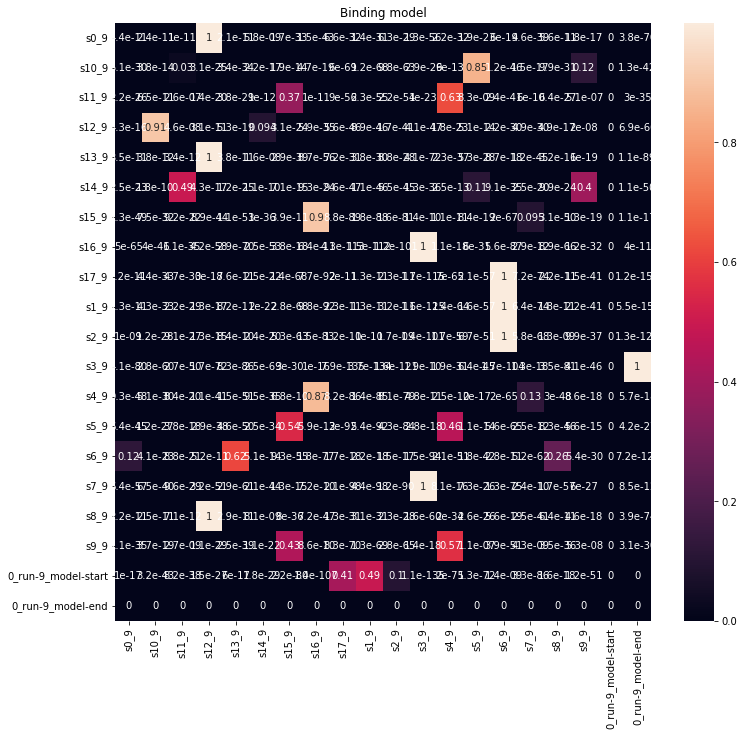

In [21]:
plt.figure(figsize=(12, 11))
ax = sns.heatmap(transition_b_df, annot=True)
ax.set_title("Binding model")

Text(0.5, 1.0, 'Immunogenicity model')

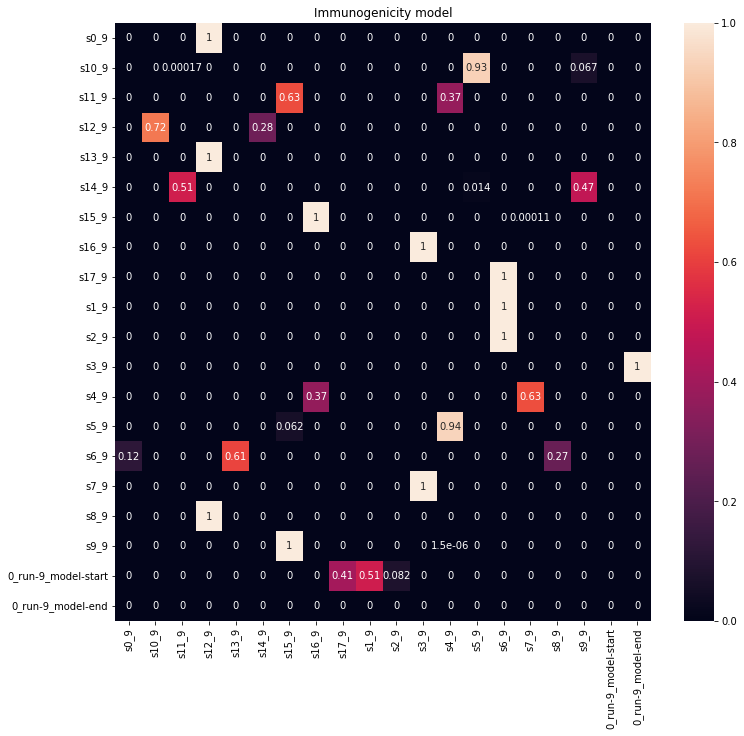

In [22]:
plt.figure(figsize=(12, 11))
ax = sns.heatmap(transition_i_df, annot=True)
ax.set_title("Immunogenicity model")

<AxesSubplot:>

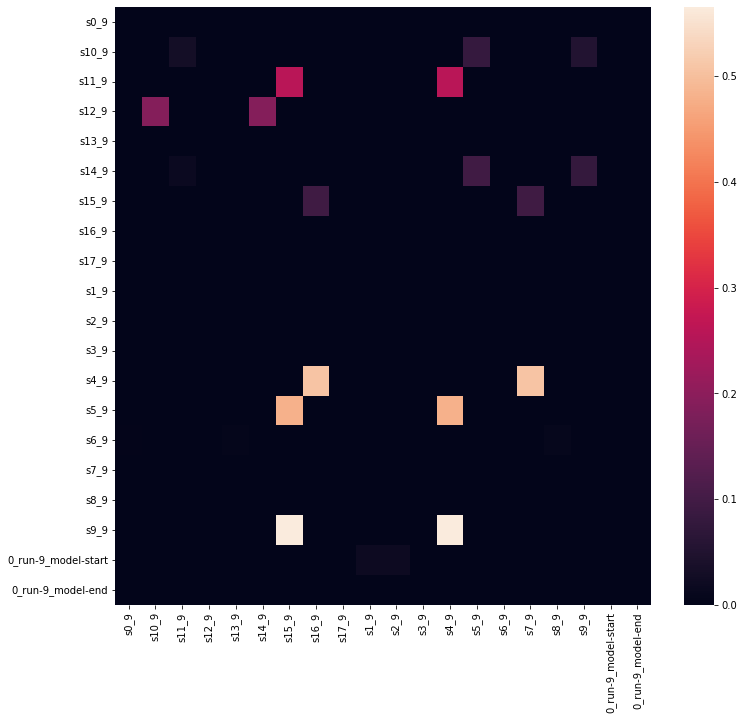

In [23]:
plt.figure(figsize=(12, 11))
sns.heatmap(diff_df)

<AxesSubplot:>

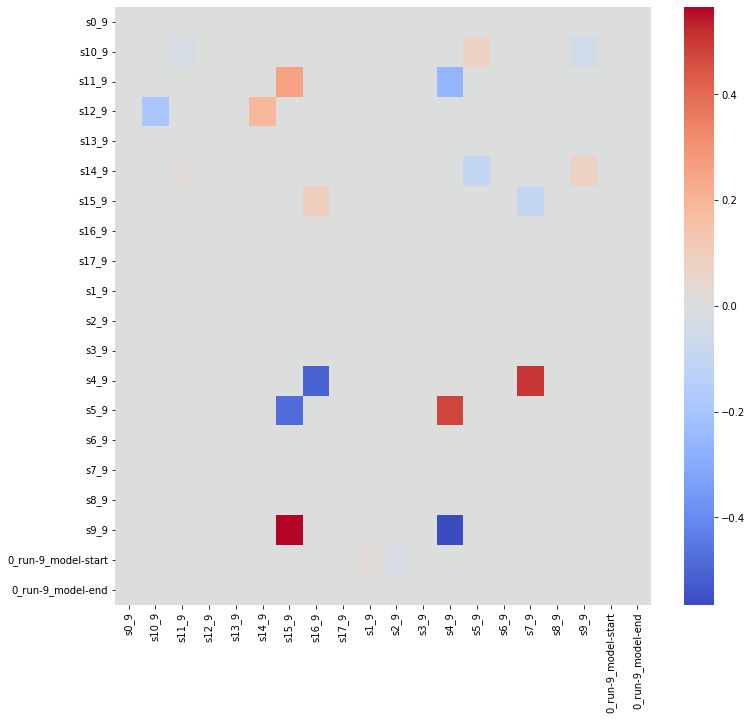

In [24]:
plt.figure(figsize=(12, 11))
sns.heatmap(diff2_df, cmap="coolwarm")

In [25]:
hottest_areas = np.ma.MaskedArray(diff2_df, np.abs(diff2_df) < 0)
X, Y = hottest_areas.nonzero()

hottest_points = [(x,y, value) for x, y , value in zip(X, Y, [hottest_areas[i,j] for i,j in zip(X,Y)])]
sorted_hottest_points = list(sorted(hottest_points, key=lambda x:np.abs(x[2]), reverse=True))
#print state_names
states_b = model_binding.states
name_to_change = defaultdict(int)
name_to_level = make_levels(model_binding)
transition_to_change = defaultdict(int)
for x,y, value in sorted_hottest_points:
    print(f"{states_b[x].name} -> {states_b[y].name} : {value}")
    name_to_change[states_b[x].name] += value
    # position is level - 2
    transition_to_change[f"{name_to_level[states_b[x].name] - 2}->{name_to_level[states_b[y].name] - 2}"] += np.abs(value)


s9_9 -> s15_9 : 0.5654207769493729
s9_9 -> s4_9 : -0.5654206074380346
s4_9 -> s7_9 : 0.5070118109332362
s4_9 -> s16_9 : -0.5070118099591276
s5_9 -> s4_9 : 0.48129201108018344
s5_9 -> s15_9 : -0.481292011071837
s11_9 -> s15_9 : 0.25686656892629006
s11_9 -> s4_9 : -0.2568657909541093
s12_9 -> s14_9 : 0.189820523247743
s12_9 -> s10_9 : -0.189820456668512
s14_9 -> s5_9 : -0.09678271017104831
s15_9 -> s16_9 : 0.09490155556295887
s15_9 -> s7_9 : -0.0949015553692331
s10_9 -> s5_9 : 0.08114956351574953
s14_9 -> s9_9 : 0.07918433897006227
s10_9 -> s9_9 : -0.05142749531517858
s10_9 -> s11_9 : -0.029722068199914336
0_run-9_model-start -> s1_9 : 0.018619195672179067
0_run-9_model-start -> s2_9 : -0.018048940691488533
s14_9 -> s11_9 : 0.017598371487392017
s6_9 -> s8_9 : 0.008334297837985005
s6_9 -> s13_9 : -0.004693422082693188
s6_9 -> s0_9 : -0.0036408756751309668
0_run-9_model-start -> s17_9 : -0.0005702535484405358
s11_9 -> s9_9 : -5.067676641679377e-07
s11_9 -> s11_9 : -2.62214907675531e-07
s9_

In [26]:
for position, value in sorted(transition_to_change.items()):
    print(position, value)

-1->0 0.037238389912108136
-1->1 1.4322499623722137e-09
-1->2 7.224182423032808e-17
-1->3 1.4932201824320755e-27
-1->4 1.8087525040765508e-29
-1->5 8.238233789694302e-38
-1->6 1.9939838096644773e-75
-1->7 3.2674894979768495e-86
-1->8 1.096939567768198e-135
0->0 2.0749656215117167e-09
0->1 5.451612494766778e-09
0->2 3.3766455295497317e-09
0->3 1.3350585728641864e-15
0->4 2.414078531680946e-20
0->5 9.170048244446552e-27
0->6 1.7144302950953426e-59
0->7 5.768357800959153e-68
0->8 1.3829241799408297e-101
0->9 1.3203346274503876e-122
1->0 1.9082519205631163e-17
1->1 2.827616063022519e-11
1->2 0.01666859559580916
1->3 5.183348498340026e-11
1->4 5.124714176443594e-14
1->5 8.751774275020071e-21
1->6 2.0536806697554523e-51
1->7 5.210583970865145e-62
1->8 1.4994132387685697e-94
1->9 7.188166601129564e-120
2->0 1.1745182203728169e-27
2->1 9.854754374347177e-18
2->2 3.3952948453759533e-10
2->3 3.082176525115443e-08
2->4 3.0461423131673055e-08
2->5 2.081256366186561e-11
2->6 2.4140796927711987e-32


## 4.2 Emissions

In [27]:
def get_emission_matrix(model):
    states_list = model.states
    emission_matrix = np.zeros(shape=(len(states_list), 20))
    for i,state in enumerate(states_list):
        if state.distribution is not None:
            amino_acids = list(state.distribution.parameters[0].keys())
            emission_matrix[i, :] = list(state.distribution.parameters[0].values())
    emissions_df = pd.DataFrame(emission_matrix, columns=amino_acids, index=[state.name for state in states_list])
    return emissions_df

def get_per_position_emission_df(model, emission_matrix_df):
    # We want to get per position pictures
    name_to_level = make_levels(model)
    per_position_rows = defaultdict(list)
    per_position_df = dict()
    for state_name in emission_matrix_df.index.values:
        position = name_to_level[state_name] - 2
        per_position_rows[position].append(emission_matrix_df.loc[state_name].copy())
    for position, rows in sorted(per_position_rows.items()):
        df = pd.DataFrame(rows)
        per_position_df[position] = df
    return per_position_df
    
    

    
    
emission_df_b = get_emission_matrix(model_binding)
    
emission_df_i = get_emission_matrix(model_immunogenic)


emission_df_b.head()


,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
s0_9,0.051012,0.015092,0.021809,0.145118,0.024600,0.008903,0.013198,0.095680,0.022034,0.231611,0.022125,0.044933,0.034268,0.066578,0.044893,0.011843,0.019674,0.086445,0.006233,0.033951
s10_9,0.061289,0.007674,0.043697,0.070734,0.054207,0.062692,0.042532,0.059197,0.073634,0.097427,0.013470,0.039217,0.040285,0.046411,0.048771,0.059319,0.063920,0.063980,0.011656,0.039889
s11_9,0.025986,0.008152,0.041825,0.105834,0.074352,0.052983,0.030228,0.065953,0.041214,0.053678,0.005337,0.063769,0.154837,0.094336,0.012579,0.112889,0.005589,0.015098,0.014729,0.020632
s12_9,0.065737,0.008104,0.124275,0.148669,0.018882,0.079682,0.025217,0.026739,0.057468,0.048295,0.008886,0.050969,0.083714,0.041919,0.032087,0.080012,0.045950,0.031305,0.006870,0.015221
s13_9,0.145135,0.000788,0.118617,0.001764,0.070745,0.041988,0.031249,0.046772,0.037271,0.131421,0.040403,0.034356,0.017974,0.040152,0.010431,0.093669,0.031105,0.046399,0.036329,0.023430


<AxesSubplot:>

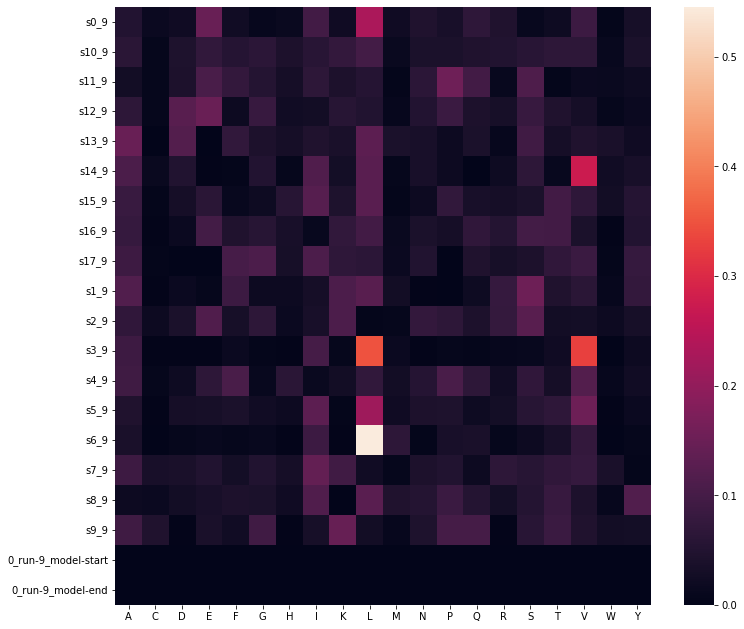

In [29]:
#heatmap
plt.figure(figsize=(12, 11))
sns.heatmap(emission_df_b)

<AxesSubplot:>

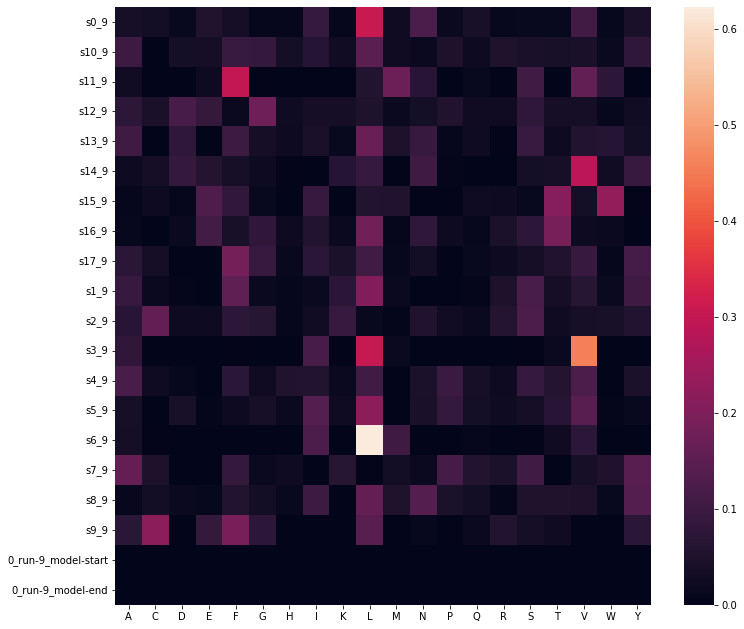

In [30]:
#heatmap
plt.figure(figsize=(12, 11))
sns.heatmap(emission_df_i)

In [31]:
per_position_emission_b_df = get_per_position_emission_df(model_binding, emission_df_b)

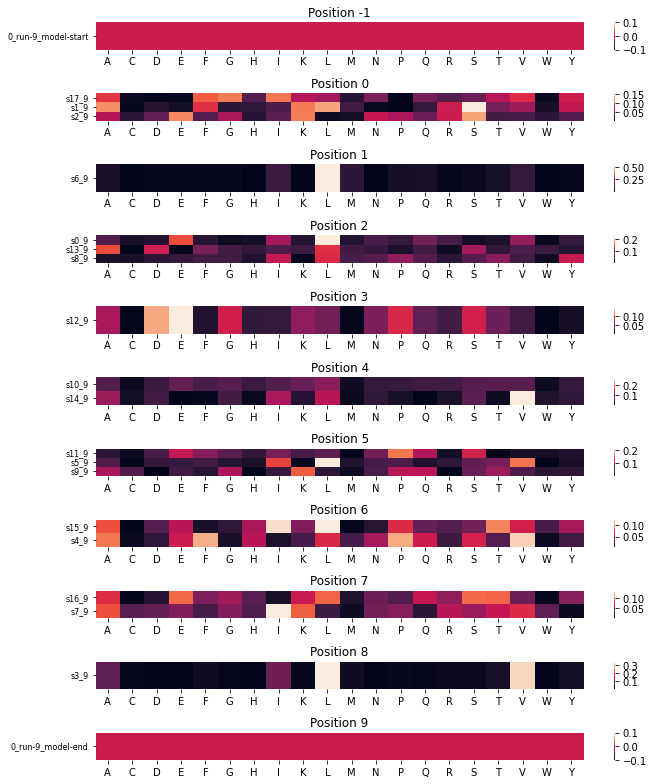

In [32]:
fig, axes = plt.subplots(nrows=len(per_position_emission_b_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_b_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()


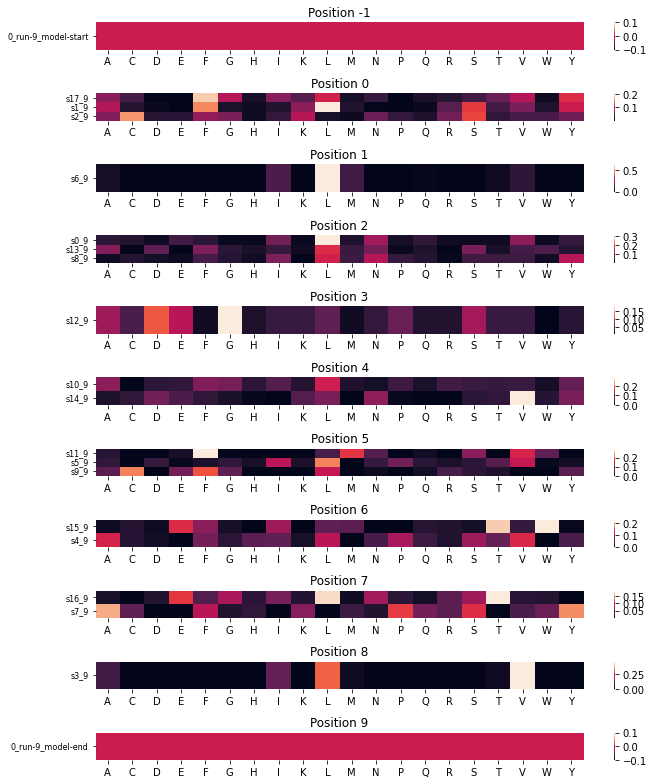

In [33]:
per_position_emission_i_df = get_per_position_emission_df(model_immunogenic, emission_df_i)
fig, axes = plt.subplots(nrows=len(per_position_emission_i_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_i_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()


## Diference

<AxesSubplot:>

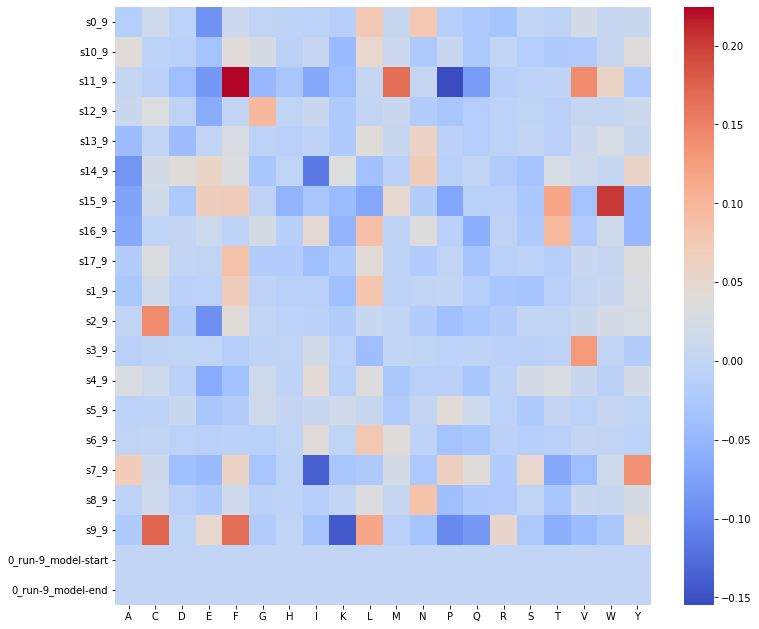

In [34]:
diff_df =  emission_df_i - emission_df_b
plt.figure(figsize=(12, 11))
sns.heatmap(diff_df, cmap="coolwarm")

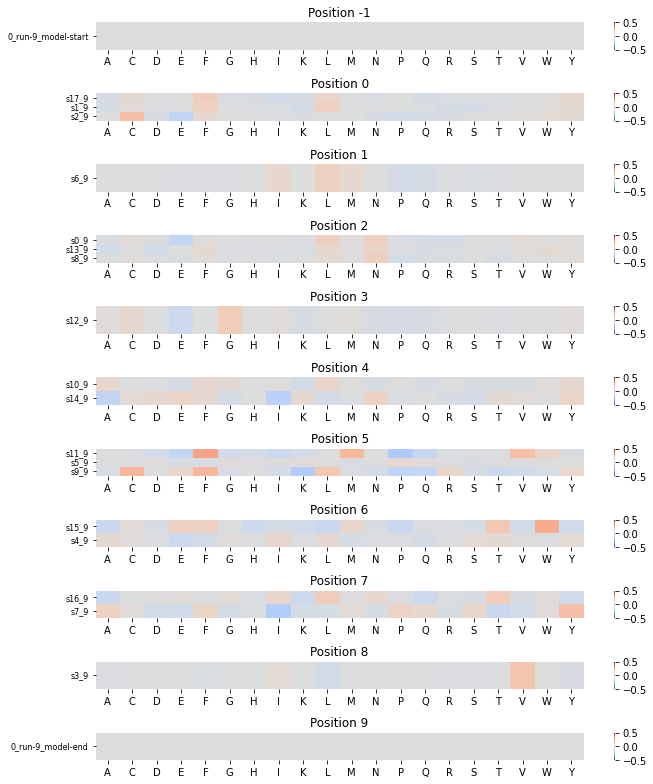

In [35]:
per_position_emission_diff_df = get_per_position_emission_df(model_binding, diff_df)
fig, axes = plt.subplots(nrows=len(per_position_emission_diff_df), figsize=(10,11))
for i, (position, df) in enumerate(sorted(per_position_emission_diff_df.items())):
    ax = axes[i]
    ax.set_title(f'Position {position}')
    g = sns.heatmap(df, ax=ax, cmap='coolwarm', vmin=-0.5, vmax=0.5)
    g.set_yticklabels(g.get_yticklabels(), rotation = 0, fontsize = 8)
plt.tight_layout()

In [36]:
per_position_emission_b_df[2].sum().values.reshape(1,-1)

array([[0.21401981, 0.03185278, 0.16797465, 0.18175365, 0.13699359,
        0.09061655, 0.06576848, 0.25537466, 0.06004768, 0.49058972,
        0.10768743, 0.13215111, 0.13699485, 0.15861049, 0.08309439,
        0.15791338, 0.13056862, 0.17405047, 0.05151519, 0.17242249]])

In [37]:
df = pd.DataFrame(per_position_emission_b_df[2].sum().values.reshape(1,-1), columns = per_position_emission_b_df[2].columns )

In [38]:
per_position_emission_b_df[2]

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
s0_9,0.051012,0.015092,0.021809,0.145118,0.024600,0.008903,0.013198,0.095680,0.022034,0.231611,0.022125,0.044933,0.034268,0.066578,0.044893,0.011843,0.019674,0.086445,0.006233,0.033951
s13_9,0.145135,0.000788,0.118617,0.001764,0.070745,0.041988,0.031249,0.046772,0.037271,0.131421,0.040403,0.034356,0.017974,0.040152,0.010431,0.093669,0.031105,0.046399,0.036329,0.023430
s8_9,0.017872,0.015973,0.027548,0.034872,0.041649,0.039725,0.021321,0.112922,0.000743,0.127558,0.045159,0.052862,0.084752,0.051881,0.027770,0.052401,0.079790,0.041206,0.008953,0.115041


In [39]:
df

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.21402,0.031853,0.167975,0.181754,0.136994,0.090617,0.065768,0.255375,0.060048,0.49059,0.107687,0.132151,0.136995,0.15861,0.083094,0.157913,0.130569,0.17405,0.051515,0.172422


<AxesSubplot:>

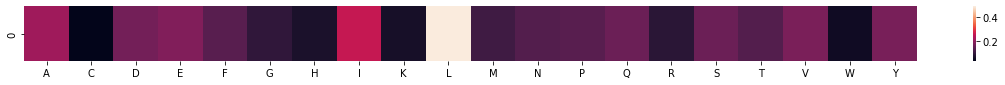

In [40]:
plt.figure(figsize=(20,1))
sns.heatmap(df)

In [41]:
import scipy
positions = list()
states = list()
state_entropies = list()
position_entropies = list()

for i, (position, df) in enumerate(sorted(per_position_emission_b_df.items())):
    df_b = df
    df_i = per_position_emission_i_df[position]
    
    sum_row_b = df_b.sum()
    sum_row_i = df_i.sum()
    sum_entropy =  scipy.stats.entropy(sum_row_i.values, sum_row_b.values)
    print(f"Position {position}")
    print(f"Position entropy: {np.round(sum_entropy,3)}")
    for (name_b, row_b), (name_i, row_i) in zip(df_b.iterrows(),df_i.iterrows()):
        assert name_b == name_i
        entropy = scipy.stats.entropy(row_i.values, row_b.values)
        if entropy ==  np.inf:
            print(f" b : {row_b.values}")
            print(f" i : {row_i.values}")
        print(f"{name_b} change -> {np.round(entropy,3)}")
        positions.append(position)
        states.append(name_b)
        state_entropies.append(np.round(entropy,3))
        position_entropies.append(np.round(sum_entropy,3))
        

result = pd.DataFrame({"position": positions, "state": states, "state entropy": state_entropies, "position entropy": position_entropies})
    

Position -1
Position entropy: nan
0_run-9_model-start change -> nan
Position 0
Position entropy: 0.199
s17_9 change -> 0.142
s1_9 change -> 0.119
s2_9 change -> 0.348
Position 1
Position entropy: 0.152
s6_9 change -> 0.152
Position 2
Position entropy: 0.117
s0_9 change -> 0.146
s13_9 change -> 0.094
s8_9 change -> 0.113
Position 3
Position entropy: 0.126
s12_9 change -> 0.126
Position 4
Position entropy: 0.089
s10_9 change -> 0.125
s14_9 change -> 0.517
Position 5
Position entropy: 0.337
s11_9 change -> 1.43
s5_9 change -> 0.093
s9_9 change -> 1.124
Position 6
Position entropy: 0.228
s15_9 change -> 0.89
s4_9 change -> 0.211
Position 7
Position entropy: 0.112
s16_9 change -> 0.324
s7_9 change -> 0.814
Position 8
Position entropy: 0.112
s3_9 change -> 0.112
Position 9
Position entropy: nan
0_run-9_model-end change -> nan


d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\scipy\stats\_entropy.py:72: RuntimeWarning: invalid value encountered in true_divide
  pk = 1.0*pk / np.sum(pk, axis=axis, keepdims=True)
d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\scipy\stats\_entropy.py:78: RuntimeWarning: invalid value encountered in true_divide
  qk = 1.0*qk / np.sum(qk, axis=axis, keepdims=True)


In [42]:
result

,position,state,state entropy,position entropy
0,-1,0_run-9_model-start,NaN,NaN
1,0,s17_9,0.142,0.199
2,0,s1_9,0.119,0.199
3,0,s2_9,0.348,0.199
4,1,s6_9,0.152,0.152
5,2,s0_9,0.146,0.117
6,2,s13_9,0.094,0.117
7,2,s8_9,0.113,0.117
8,3,s12_9,0.126,0.126
9,4,s10_9,0.125,0.089


In [43]:
result[['position', 'position entropy']].drop_duplicates()

,position,position entropy
0,-1,NaN
1,0,0.199
4,1,0.152
5,2,0.117
8,3,0.126
9,4,0.089
11,5,0.337
14,6,0.228
16,7,0.112
18,8,0.112


In [44]:
result[['position','state' ,'state entropy']]

,position,state,state entropy
0,-1,0_run-9_model-start,NaN
1,0,s17_9,0.142
2,0,s1_9,0.119
3,0,s2_9,0.348
4,1,s6_9,0.152
5,2,s0_9,0.146
6,2,s13_9,0.094
7,2,s8_9,0.113
8,3,s12_9,0.126
9,4,s10_9,0.125


In [45]:
# We want to get per position pictures
name_to_level = make_levels(model_binding)

per_position_rows = defaultdict(list)
for state_name in diff_df.index.values:

    position = name_to_level[state_name] - 2
    per_position_rows[position].append(diff_df.loc[state_name].copy())

# Evaluare paths

## Model binding
### Generated_data

In [20]:
generated_df_repr_db = pivot_data_dict['Generated']['db']['mb']
generated_df_repr_di = pivot_data_dict['Generated']['di']['mb']

In [23]:
from collections import defaultdict
def get_path_changes(df_b, df_i, paths_df):
    path_index_to_score_db = defaultdict(int)
    for index, row in df_b.iterrows():
        for path_index, column_value in enumerate(row):
            path_index_to_score_db[path_index] += column_value
            # if column_value > treshold:
            #     path_index_to_score_db[path_index] += 1

    path_index_to_score_di = defaultdict(int)
    for index, row in df_i.iterrows():
        for path_index, column_value in enumerate(row):
            path_index_to_score_di[path_index] += column_value
            # if column_value > treshold:
            #     path_index_to_score_di[path_index] += 1
                
    #normalize by size of sample

    for path_index in path_index_to_score_db:
        path_index_to_score_db[path_index] = path_index_to_score_db[path_index] / len(df_b)


    for path_index in path_index_to_score_di:
        path_index_to_score_di[path_index] = path_index_to_score_di[path_index] / len(df_i)
    dfb = pd.DataFrame.from_dict(path_index_to_score_db, orient='index', columns=["value"])
    dfi = pd.DataFrame.from_dict(path_index_to_score_di, orient='index', columns=["value"])
    merge_df = pd.merge(dfb, dfi, left_index=True, right_index=True, suffixes=['_b','_i'])
    merge_df['diff'] = merge_df['value_i'].subtract(merge_df['value_b'], fill_value=0)
    
    paths_df_copy = paths_df.copy()
    paths_df_copy[['start'] +  [f'state_{i}' for i in range(target_length)] + ['end'] ] = pd.DataFrame(paths_df_copy['path'].to_list(), index=paths_df_copy.index)
    paths_df_copy= paths_df_copy.drop(columns=['start', 'end', 'path'])
    

    total_df = pd.merge(merge_df, paths_df_copy,  left_index=True, right_index=True, suffixes=['_b','_i'])
    return total_df

In [24]:
total_df = get_path_changes(generated_df_repr_db, generated_df_repr_di, df_b_paths).sort_values('diff')
total_df.to_csv("generated_paths_changes.csv")

In [25]:
total_df

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
149,-25.969090,-25.603615,0.365475,-7.613828,s15_9,s12_9,s4_9,s1_9,s2_9,s9_9,s13_9,s10_9,s16_9
151,-30.040797,-29.674544,0.366253,-11.960691,s15_9,s12_9,s4_9,s1_9,s2_9,s14_9,s13_9,s10_9,s16_9
147,-25.738450,-25.358236,0.380214,-8.124714,s15_9,s12_9,s4_9,s1_9,s2_9,s5_9,s13_9,s10_9,s16_9
145,-27.776398,-27.393588,0.382810,-7.533192,s15_9,s12_9,s4_9,s1_9,s2_9,s0_9,s13_9,s10_9,s16_9
53,-27.125630,-26.741677,0.383953,-6.551041,s15_9,s7_9,s4_9,s1_9,s2_9,s9_9,s13_9,s10_9,s16_9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
136,-32.050687,-30.787803,1.262884,-5.305442,s15_9,s12_9,s3_9,s11_9,s17_9,s0_9,s8_9,s10_9,s16_9
44,-35.025276,-33.761248,1.264028,-6.215325,s15_9,s7_9,s3_9,s11_9,s17_9,s9_9,s8_9,s10_9,s16_9
46,-34.672202,-33.407396,1.264806,-2.622707,s15_9,s7_9,s3_9,s11_9,s17_9,s14_9,s8_9,s10_9,s16_9
42,-39.747452,-38.468684,1.278767,-2.975018,s15_9,s7_9,s3_9,s11_9,s17_9,s5_9,s8_9,s10_9,s16_9


### Train data

In [50]:
train_df_repr_db = pivot_data_dict['Train']['db']['mb']
train_df_repr_di = pivot_data_dict['Train']['di']['mb']

In [51]:
total_df = get_path_changes(train_df_repr_db, train_df_repr_di, df_b_paths).sort_values('diff')
total_df.to_csv("train_paths_changes.csv")

In [52]:
total_df.sort_values('diff')

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
174,-27.759870,-27.825757,-0.065887,-7.652231,s17_9,s6_9,s8_9,s12_9,s10_9,s9_9,s15_9,s7_9,s3_9
150,-29.608715,-29.671476,-0.062761,-8.410397,s17_9,s6_9,s0_9,s12_9,s10_9,s9_9,s15_9,s7_9,s3_9
178,-30.016460,-30.046735,-0.030275,-9.185800,s17_9,s6_9,s8_9,s12_9,s10_9,s11_9,s15_9,s7_9,s3_9
154,-31.865306,-31.892454,-0.027148,-9.943967,s17_9,s6_9,s0_9,s12_9,s10_9,s11_9,s15_9,s7_9,s3_9
172,-27.523992,-27.540213,-0.016221,-7.110127,s17_9,s6_9,s8_9,s12_9,s10_9,s9_9,s4_9,s7_9,s3_9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,-32.682150,-31.927068,0.755082,-8.060976,s2_9,s6_9,s13_9,s12_9,s14_9,s5_9,s15_9,s16_9,s3_9
69,-33.757965,-32.982866,0.775098,-4.861217,s1_9,s6_9,s13_9,s12_9,s14_9,s11_9,s4_9,s16_9,s3_9
141,-33.550860,-32.764498,0.786362,-6.451250,s2_9,s6_9,s13_9,s12_9,s14_9,s11_9,s4_9,s16_9,s3_9
61,-33.664951,-32.871466,0.793485,-6.679571,s1_9,s6_9,s13_9,s12_9,s14_9,s5_9,s4_9,s16_9,s3_9


## Model Immunogenic
### Generated data

In [26]:
generated_df_repr_db = pivot_data_dict['Generated']['db']['mi']
generated_df_repr_di = pivot_data_dict['Generated']['di']['mi']

In [27]:
total_df = get_path_changes(generated_df_repr_db, generated_df_repr_di, df_i_paths).sort_values('diff')
total_df.to_csv("generated_paths_changes_mi.csv")

In [28]:
df_i_paths['path'].values

array([list(['1_run-9_model-start', 's15_9', 's7_9', 's3_9', 's11_9', 's17_9', 's14_9', 's8_9', 's10_9', 's16_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's15_9', 's7_9', 's3_9', 's11_9', 's2_9', 's5_9', 's8_9', 's10_9', 's16_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's15_9', 's12_9', 's4_9', 's1_9', 's6_9', 's0_9', 's8_9', 's10_9', 's16_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's15_9', 's7_9', 's4_9', 's1_9', 's6_9', 's0_9', 's8_9', 's10_9', 's16_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's15_9', 's12_9', 's4_9', 's11_9', 's17_9', 's14_9', 's8_9', 's10_9', 's16_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's15_9', 's7_9', 's4_9', 's11_9', 's17_9', 's14_9', 's8_9', 's10_9', 's16_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's15_9', 's12_9', 's4_9', 's1_9', 's6_9', 's9_9', 's13_9', 's10_9', 's16_9', '1_run-9_model-end']),
       list(['1_run-9_model-start', 's15_9', 's7

### Train data

In [29]:
train_df_repr_db = pivot_data_dict['Train']['db']['mi']
train_df_repr_di = pivot_data_dict['Train']['di']['mi']

In [30]:
total_df = get_path_changes(train_df_repr_db, train_df_repr_di, df_i_paths).sort_values('diff')
total_df.to_csv("train_paths_changes_mi.csv")

In [31]:
total_df.head()

,value_b,value_i,diff,prob,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8
20,-7918.752036,-72.756158,7845.995877,-6.144340,s15_9,s7_9,s3_9,s11_9,s6_9,s0_9,s8_9,s10_9,s16_9
84,-7913.413760,-66.468688,7846.945071,-12.379250,s15_9,s12_9,s3_9,s11_9,s6_9,s0_9,s8_9,s10_9,s16_9
21,-7905.450889,-58.499769,7846.951119,-8.028155,s15_9,s7_9,s3_9,s11_9,s6_9,s0_9,s13_9,s10_9,s16_9
29,-7917.995425,-70.685598,7847.309827,-4.386782,s15_9,s7_9,s3_9,s11_9,s17_9,s9_9,s13_9,s10_9,s16_9
25,-7911.949869,-64.590454,7847.359416,-3.766186,s15_9,s7_9,s3_9,s11_9,s17_9,s0_9,s8_9,s10_9,s16_9


In [32]:
train_df_repr_di

path_index,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
peptide,,,,,,,,,,,,,,,,,,,,,
AIISGDSPV,-93.061128,-89.876479,-124.050432,-118.637738,-54.627846,-46.686925,-113.486808,-81.625564,-78.440915,-35.103293,...,-114.356523,-77.877722,-74.693073,-31.355451,-23.414530,-74.482331,-71.297682,-39.042893,-31.101972,-94.799038
AIMDKNIIL,-53.308256,-51.189985,-34.793105,-30.446789,-97.195559,-90.321016,-54.445773,-68.568785,-66.450514,-104.367099,...,-52.777437,-62.282892,-60.164620,-98.081205,-91.206662,-51.913288,-49.795016,-98.794434,-91.919891,-52.941832
AIMDKNIML,-54.081446,-51.963175,-35.566295,-31.219979,-97.968749,-91.094205,-55.218963,-69.341975,-67.223703,-105.140289,...,-53.550627,-63.056082,-60.937810,-98.854395,-91.979852,-52.686478,-50.568206,-99.567624,-92.693081,-53.715021
AINGVMWTV,-60.112889,-63.370105,-45.277501,-46.306672,-106.996477,-105.497421,-41.432127,-66.522329,-69.779544,-105.316927,...,-26.972716,-47.445361,-50.702577,-86.239960,-84.740904,-36.661760,-39.918975,-86.539191,-85.040135,-17.872024
AIYDTMQYV,-54.162239,-52.975655,-39.326851,-35.912223,-101.045827,-95.102972,-35.481477,-52.254665,-51.068081,-91.049263,...,-34.821734,-46.977365,-45.790781,-85.771963,-79.829108,-42.531179,-41.344595,-92.408611,-86.465755,-23.741443
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YTMDGEYRL,-77.572714,-47.354076,-79.276384,-46.829701,-88.111116,-53.136205,-77.361555,-66.137150,-35.918511,-68.586562,...,-76.184493,-60.342531,-30.123892,-62.791943,-27.817033,-56.947140,-26.728501,-70.479385,-35.504475,-56.627008
YVDDVVLGA,-44.990645,-29.944689,-46.378713,-29.104713,-56.478813,-36.676586,-46.530467,-51.400084,-36.354129,-54.799264,...,-56.031169,-56.283230,-41.237275,-59.682410,-39.880183,-45.499629,-30.453674,-59.981642,-40.179415,-46.930478
YVLDHLIVV,-31.717030,-29.598758,-32.080623,-27.734307,-41.561078,-34.686535,-31.124034,-31.691114,-29.572843,-33.446174,...,-41.516191,-37.465714,-35.347443,-39.220774,-32.346231,-38.395086,-36.276814,-51.232979,-44.358436,-37.693117


## Some statistics test with known answer

In [58]:
df = pd.read_csv('D:\\Sandbox\onesnp.csv', header=None, names=['acid', 'value'])
df.head()

,acid,value
0,C,1
1,G,0
2,G,0
3,T,1
4,G,0


In [59]:
from scipy.stats import chi2

def get_sz(a, b):
    return len(df[(df.acid.astype('str') == a) & (df["value"] == b)])

def xi(a, b):
    m1 = 0
    for i in ["A", "C", "G", "T"]:
        m1 += get_sz(i, b)
    m2 = get_sz(a, 0) + get_sz(a, 1)

    n = len(df)
    return (((get_sz(a, b) - m1 * m2 / n) ** 2) / (m1 * m2 / n))

def glob_xi():
    res = 0
    for i in [0, 1]:
        for j in ["A", "C", "G", "T"]:
            res += xi(j, i)
    return res

print("A:", get_sz('A', 1), get_sz('A', 0))
print("C:", get_sz('C', 1), get_sz('C', 0))
print("G:", get_sz('G', 1), get_sz('G', 0))
print("T:", get_sz('T', 1), get_sz('T', 0))

print("chi^2:", glob_xi())
print("p-value:", 1 - chi2.cdf(glob_xi(), 3))

A: 1199 1224
C: 1266 1259
G: 1253 1286
T: 1276 1237
chi^2: 1.2971142104271318
p-value: 0.7298184494688893


In [60]:
crosstab = pd.crosstab( df['value'],df['acid'])
crosstab

acid,A,C,G,T
value,,,,
0,1224,1259,1286,1237
1,1199,1266,1253,1276


## with statsmodels

In [61]:
import statsmodels.api as sm
table = sm.stats.Table(crosstab)

In [62]:
rslt = table.test_nominal_association()
print("p-value" , rslt.pvalue)
table.chi2_contribs

p-value 0.7298184494688896


acid,A,C,G,T
value,,,,
0,0.100596,0.019897,0.176471,0.350815
1,0.100838,0.019945,0.176895,0.351658


## with sklearn

In [63]:
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

In [64]:
stat, p, dof, expected = chi2_contingency(crosstab)
stat, p, dof, expected

(1.2971142104271318,
 0.7298184494688893,
 3,
 array([[1212.9538, 1264.015 , 1271.0234, 1258.0078],
        [1210.0462, 1260.985 , 1267.9766, 1254.9922]]))

## For binders

In [65]:
binders = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][split_num][target_length]
non_binders = per_allele_per_kfold_per_length_non_binders_train[ALLELES[0]][split_num][target_length]

In [66]:
non_binders_df = pd.DataFrame([list(peptide) for peptide in non_binders])
non_binders_df['binder'] = 0
binders_df = pd.DataFrame([list(peptide) for peptide in binders])
binders_df['binder'] = 1


In [67]:
total_df = pd.concat([binders_df, non_binders_df])

In [68]:
total_df

,0,1,2,3,4,5,6,7,8,binder
0,T,L,Q,S,K,D,F,K,L,1
1,L,L,L,E,V,S,E,E,L,1
2,V,V,V,K,I,L,K,P,V,1
3,A,V,M,Q,E,V,P,L,A,1
4,A,V,N,A,A,V,Q,R,V,1
...,...,...,...,...,...,...,...,...,...,...
5682,W,E,Y,W,G,A,Q,L,N,0
5683,R,T,R,G,P,L,G,I,L,0
5684,R,A,R,I,K,T,R,L,F,0
5685,K,L,D,F,I,R,N,T,K,0


In [69]:
amino_acids = list('ACDEFGHIKLMNPQRSTVWY')

In [70]:
from scipy.stats import chi2_contingency
crosstab = pd.crosstab(total_df['binder'],  total_df[2])
rslt_scipy = chi2_contingency(crosstab)
b = sm.stats.Table(crosstab).test_nominal_association()
b.pvalue


0.0

In [71]:
p_values = list()
p_values_scipy = list()
chi2_contribs = list()
for position in range(target_length):
    print(f"position {position}")
    crosstab = pd.crosstab(total_df[position], total_df['binder'])
    table = sm.stats.Table(crosstab)
    rslt = table.test_nominal_association()
    print("p-value nominal" , rslt.pvalue)
    p_values.append(rslt.pvalue)
    stat, p, dof, expected = chi2_contingency(crosstab)
    p_values_scipy.append(p)
    # rslt = table.test_ordinal_association()
    # print("p-value ordinal" , rslt.pvalue)
    # print(table.chi2_contribs)
    chi2_contribs.append(table.chi2_contribs)
    
          

position 0
p-value nominal 0.0
position 1
p-value nominal 0.0
position 2
p-value nominal 0.0
position 3
p-value nominal 0.0
position 4
p-value nominal 0.0
position 5
p-value nominal 0.0
position 6
p-value nominal 0.0
position 7
p-value nominal 0.0
position 8
p-value nominal 0.0


In [72]:
crosstab

binder,0,1
8,,
A,390,2167
C,50,102
D,73,59
E,106,101
F,425,407
G,122,115
H,71,59
I,535,2344
K,365,193


In [73]:
from statsmodels.stats.multitest import multipletests
rejects, p_values, significance1, significance2 = multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


In [74]:
pd.DataFrame({"position":[i for i in range(target_length)],"p-value":p_values, "reject H0": rejects})

,position,p-value,reject H0
0,0,0.000000e+00,True
1,1,0.000000e+00,True
2,2,4.616229e-176,True
3,3,7.679573e-230,True
4,4,3.302684e-40,True
5,5,1.741724e-251,True
6,6,6.438037e-192,True
7,7,4.251359e-161,True
8,8,0.000000e+00,True


## For immune peptides

In [75]:
imm = per_allele_per_kfold_per_length_immunogenic_train[ALLELES[0]][split_num][target_length]
non_imm = per_allele_per_kfold_per_length_non_immunogenic_train[ALLELES[0]][split_num][target_length]

In [76]:
non_imm_df = pd.DataFrame([list(peptide) for peptide in non_imm])
non_imm_df['imm'] = 0
imm_df = pd.DataFrame([list(peptide) for peptide in imm])
imm_df['imm'] = 1


In [77]:
total_df = pd.concat([imm_df, non_imm_df])

In [78]:
total_df

,0,1,2,3,4,5,6,7,8,imm
0,T,L,W,C,S,P,I,K,V,1
1,N,M,F,T,P,Y,I,G,V,1
2,L,L,L,G,L,M,I,L,L,1
3,F,T,L,V,A,P,V,S,I,1
4,K,L,S,E,G,D,L,L,A,1
...,...,...,...,...,...,...,...,...,...,...
347,I,L,F,L,F,F,C,F,V,0
348,W,L,I,T,F,V,L,N,A,0
349,F,L,P,A,Y,L,N,S,L,0
350,V,L,L,A,L,V,L,L,L,0


In [79]:
p_values = list()
p_values_scipy = list()
chi2_contribs = list()
for position in range( target_length):
    print(f"position {position}")
    df_copy = total_df.copy()[[position, "imm"]]
    crosstab = pd.crosstab(df_copy[position], df_copy['imm'])
    table = sm.stats.Table(crosstab)
    rslt = table.test_nominal_association()
    print("p-value nominal" , rslt.pvalue)
    rslt = table.test_ordinal_association()
    print("p-value ordinal" , rslt.pvalue)
    stat, p, dof, expected = chi2_contingency(crosstab)
    p_values_scipy.append(p)
    chi2_contribs.append(table.chi2_contribs)
    

position 0
p-value nominal 0.3006046229771133
p-value ordinal 0.8795366720276284
position 1
p-value nominal 0.005804262731529453
p-value ordinal 0.43222726625311514
position 2
p-value nominal 0.06230208219212463
p-value ordinal 0.044195758793265004
position 3
p-value nominal 9.90934518818598e-06
p-value ordinal 0.015844692907315487
position 4
p-value nominal 0.08393153398839426
p-value ordinal 0.10288481825528822
position 5
p-value nominal 0.22776502185138114
p-value ordinal 0.012735044754480855
position 6
p-value nominal 0.002768752543128361
p-value ordinal 0.0004157001000506472
position 7
p-value nominal 0.013633049686710308
p-value ordinal 0.041002406326065166
position 8
p-value nominal 0.00128909000149946
p-value ordinal 0.002057482794788115


In [80]:
from statsmodels.stats.multitest import multipletests
rejects, p_values, significance1, significance2 = multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


In [81]:
pd.DataFrame({"position":[i for i in range(target_length)],"p-value":p_values, "reject H0": rejects})

,position,p-value,reject H0
0,0,0.455530,False
1,1,0.001116,True
2,2,0.249208,False
3,3,0.000079,True
4,4,0.251795,False
5,5,0.455530,False
6,6,0.016613,True
7,7,0.068165,False
8,8,0.000054,True


In [82]:
from statsmodels.stats.multitest import multipletests
multipletests(pvals=p_values_scipy, alpha=0.05, method='holm')


(array([False,  True, False,  True, False, False,  True, False,  True]),
 array([4.55530044e-01, 1.11620141e-03, 2.49208329e-01, 7.92747615e-05,
        2.51794602e-01, 4.55530044e-01, 1.66125153e-02, 6.81652484e-02,
        5.44742406e-05]),
 0.005683044988048058,
 0.005555555555555556)

In [83]:
chi2_contribs[7]

imm,0,1
7,,
A,0.108632,0.095835
C,0.033425,0.029488
D,0.004708,0.004153
E,0.129522,0.114265
F,0.928890,0.819472
G,0.031900,0.028142
H,0.048119,0.042451
I,0.092062,0.081218
K,0.269897,0.238105


In [84]:
total_df

,0,1,2,3,4,5,6,7,8,imm
0,T,L,W,C,S,P,I,K,V,1
1,N,M,F,T,P,Y,I,G,V,1
2,L,L,L,G,L,M,I,L,L,1
3,F,T,L,V,A,P,V,S,I,1
4,K,L,S,E,G,D,L,L,A,1
...,...,...,...,...,...,...,...,...,...,...
347,I,L,F,L,F,F,C,F,V,0
348,W,L,I,T,F,V,L,N,A,0
349,F,L,P,A,Y,L,N,S,L,0
350,V,L,L,A,L,V,L,L,L,0


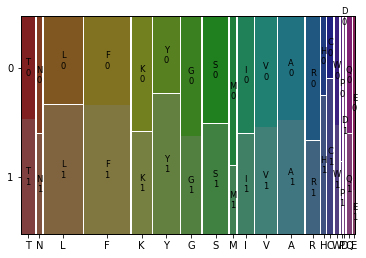

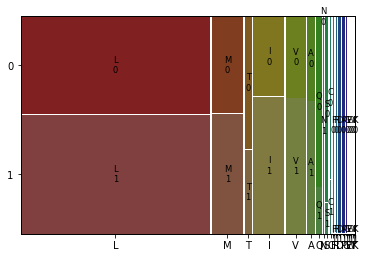

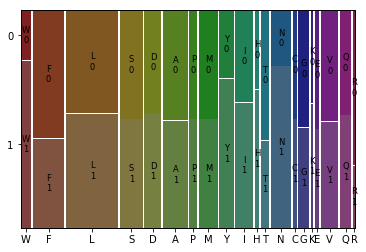

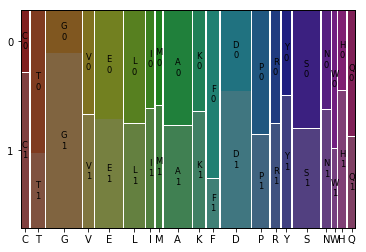

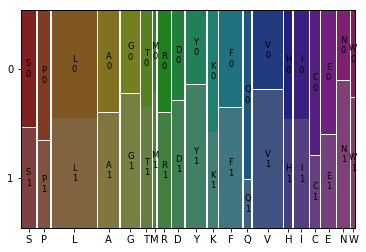

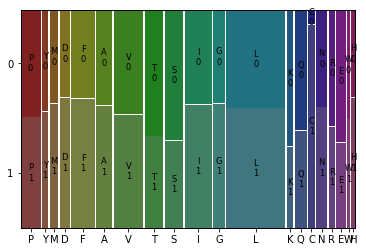

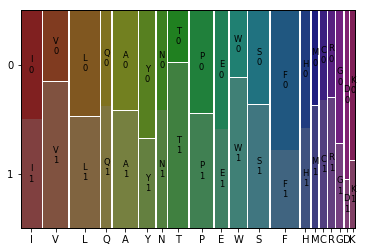

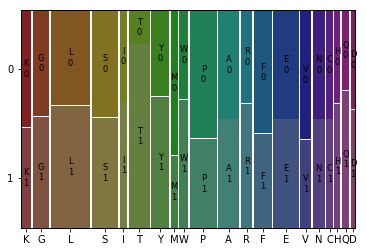

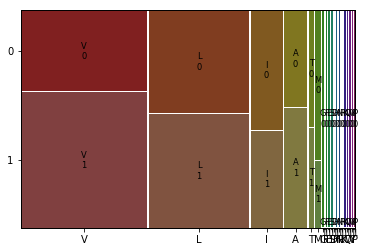

In [85]:
from statsmodels.graphics.mosaicplot import mosaic
for position in range(0,target_length):
    fig, _ = mosaic(total_df, index=[position, "imm"])

# Motifs for top paths

In [33]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None


def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    
    per_allele_decoy[allele_name] = decoy_df.copy()[decoy_df['length'] == target_length]

In [34]:
decoy_data = per_allele_decoy[ALLELES[0]]
len(decoy_data)

401984

In [35]:
decoy_data['b_score'] = [model_binding.log_probability(peptide) for peptide in decoy_data['peptide'].values]
decoy_data['i_score'] = [model_immunogenic.log_probability(peptide) for peptide in decoy_data['peptide'].values]
decoy_data['diff_score'] =  decoy_data['i_score'] - decoy_data['b_score']

In [36]:
decoy_data

,peptide,length,b_score,i_score,diff_score
10,QYPSESSVL,9,-27.085889,-inf,-inf
14,EQSHRPFLM,9,-28.965189,-32.882110,-3.916921
17,MIRNILLMH,9,-30.285462,-inf,-inf
22,PGTASAAHR,9,-31.143010,-inf,-inf
24,KMFTPPSES,9,-26.700995,-27.951638,-1.250643
...,...,...,...,...,...
1999983,ITGTKEGIE,9,-31.783248,-inf,-inf
1999986,KAKRAVQRG,9,-28.867537,-inf,-inf
1999993,SPLGPWLSS,9,-27.421174,-inf,-inf
1999995,ILLLIDIEQ,9,-25.174517,-inf,-inf


In [37]:
count = 400
top = decoy_data.sort_values('diff_score', ascending=False)[:count]
bottom = decoy_data.sort_values('diff_score', ascending=True)[:count]
df = decoy_data.sort_values('diff_score', ascending=True)
bottom_not_inf = df[~np.isinf(df['diff_score'])][:count]

In [39]:
top[['peptide', 'b_score']]

,peptide,b_score
904545,FVAGLGWEV,-23.125447
1817766,CMNRCCNAT,-33.759543
571270,FVNALMFWV,-26.102876
1529984,CVNGVCICF,-32.658429
1143749,CILSVCGWA,-30.267384
...,...,...
1214225,LAMTNGAWV,-27.019144
1248876,ILAGLLCMV,-22.889236
1647320,IAMALMGGI,-27.558315
1496137,FLNLYFLVI,-23.681333


In [40]:
top[['peptide', 'i_score']]

,peptide,i_score
904545,FVAGLGWEV,-16.345156
1817766,CMNRCCNAT,-27.301018
571270,FVNALMFWV,-19.827067
1529984,CVNGVCICF,-26.629592
1143749,CILSVCGWA,-24.360633
...,...,...
1214225,LAMTNGAWV,-24.099106
1248876,ILAGLLCMV,-19.977121
1647320,IAMALMGGI,-24.646963
1496137,FLNLYFLVI,-20.772378


In [43]:
import logomaker


def make_logo(df):
    peptides = df['peptide'].values
    matrix = logomaker.alignment_to_matrix(peptides)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    result = ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',color_scheme='chemistry')
    return result

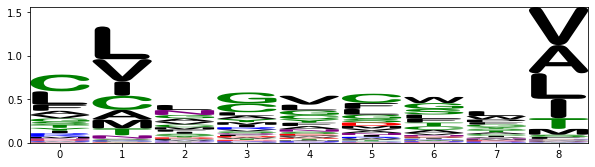

In [44]:
make_logo(top)

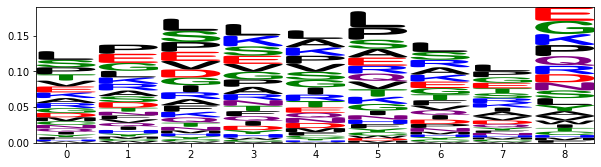

In [45]:
make_logo(bottom)

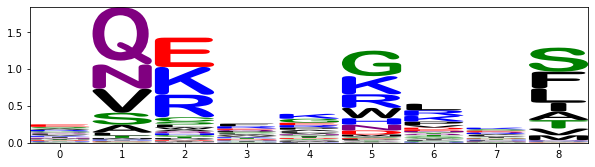

In [46]:
make_logo(bottom_not_inf)

# Top binders. Same analysis

In [47]:
top_percent_binding_value = np.percentile(decoy_data['b_score'].values, 98)
top_percent_binding_value

-22.80991709921384

In [48]:
len(decoy_data[decoy_data['b_score'] > top_percent_binding_value])

8040

In [49]:
selected_decoy_data = decoy_data[decoy_data['b_score'] > top_percent_binding_value].copy()

In [50]:
count = 300
top = selected_decoy_data.sort_values('diff_score', ascending=False)[:count]
bottom = selected_decoy_data.sort_values('diff_score', ascending=True)[:count]
df = selected_decoy_data.sort_values('diff_score', ascending=True)
bottom_not_inf = df[~np.isinf(df['diff_score'])][:count]

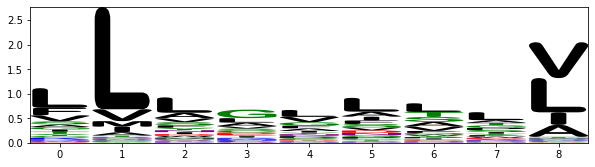

In [51]:
make_logo(top)

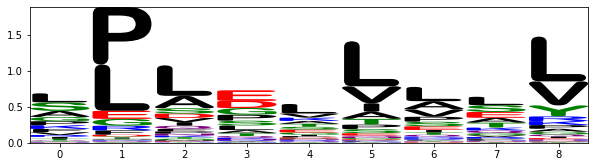

In [52]:
make_logo(bottom)

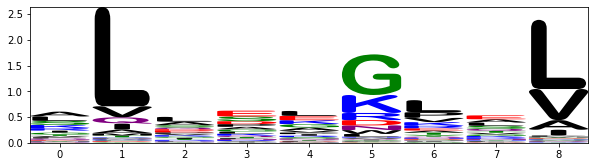

In [53]:
make_logo(bottom_not_inf)

## Same for training data

In [54]:
train_df_repr_db = pivot_data_dict['Train']['db']['mb']
train_df_repr_di = pivot_data_dict['Train']['di']['mb']

In [55]:


train_df_repr_db['b_score'] =  [model_binding.log_probability(peptide) for peptide in train_df_repr_db.index.values]
train_df_repr_di['b_score'] =  [model_binding.log_probability(peptide) for peptide in train_df_repr_di.index.values]

train_df_repr_db['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in train_df_repr_db.index.values]
train_df_repr_di['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in train_df_repr_di.index.values]

train_df_repr_db['peptide'] = train_df_repr_db.index.values
train_df_repr_di['peptide'] = train_df_repr_di.index.values

In [56]:
train_df_repr_db['diff_score'] =  train_df_repr_db['i_score'] - train_df_repr_db['b_score']
train_df_repr_db

path_index,0,1,2,3,4,5,6,7,8,9,...,186,187,188,189,190,191,b_score,i_score,peptide,diff_score
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-31.466182,-28.977603,-32.107812,-27.681458,-31.277003,-26.590527,-33.005973,-30.694144,-31.781630,-29.293051,...,-39.268390,-34.842037,-33.224643,-28.538168,-32.903480,-30.591651,-23.824433,-25.966422,AAAAGRKTL,-2.141989
AAAAKVPEV,-28.577813,-25.601316,-28.203355,-23.289083,-29.976912,-24.802518,-30.407489,-27.607742,-29.984166,-27.007668,...,-36.778538,-31.864266,-33.339157,-28.164763,-31.719600,-28.919853,-21.251124,-23.557499,AAAAKVPEV,-2.306375
AAAANPLAL,-31.273683,-30.896453,-28.140012,-25.825007,-27.946613,-25.371486,-27.871983,-27.671502,-32.431121,-32.053890,...,-35.289971,-32.974966,-29.883633,-27.308506,-27.758870,-27.558389,-22.567341,-22.836377,AAAANPLAL,-0.269036
AAAAPRAVA,-32.629809,-32.818368,-33.271439,-31.522224,-32.440630,-30.431293,-34.169600,-34.534909,-30.332113,-30.520672,...,-37.769375,-36.020160,-31.725628,-29.716291,-31.404465,-31.769774,-25.333092,-27.219569,AAAAPRAVA,-1.886477
AAAAVIPTV,-29.304756,-26.328259,-28.248757,-23.334485,-30.186977,-25.012583,-32.363998,-29.564251,-31.416808,-28.440311,...,-33.659864,-28.745592,-30.385146,-25.210752,-30.512034,-27.712286,-21.165288,-22.334559,AAAAVIPTV,-1.169271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYIFIPSKF,-39.518356,-37.338898,-36.384685,-32.267452,-36.191285,-31.813930,-36.116655,-34.113947,-39.891217,-37.711759,...,-43.260704,-39.143471,-37.854366,-33.477011,-35.729603,-33.726894,-29.445402,-inf,YYIFIPSKF,-inf
YYLNDLERI,-31.606674,-28.782306,-31.240193,-26.478051,-31.778539,-26.756274,-36.734074,-34.086456,-32.758769,-29.934401,...,-43.750934,-38.988792,-39.076341,-34.054077,-41.981743,-39.334125,-25.132699,-inf,YYLNDLERI,-inf
YYNKVSTVF,-35.231505,-34.012753,-36.088868,-32.932343,-34.733259,-31.316612,-38.098241,-37.056240,-37.343556,-36.124805,...,-42.495604,-39.339079,-35.927057,-32.510409,-37.241905,-36.199904,-29.063703,-inf,YYNKVSTVF,-inf


In [57]:
train_df_repr_db[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
AAAAGRKTL,-23.824433,-25.966422,-2.141989
AAAAKVPEV,-21.251124,-23.557499,-2.306375
AAAANPLAL,-22.567341,-22.836377,-0.269036
AAAAPRAVA,-25.333092,-27.219569,-1.886477
AAAAVIPTV,-21.165288,-22.334559,-1.169271
AAADFTAKV,-21.989585,-23.056359,-1.066774
AAADYIPTV,-21.139382,-21.345731,-0.206349
AAAESLLKA,-21.713335,-23.080291,-1.366957
AAAESSTSL,-21.597920,-22.852664,-1.254744


In [58]:
top_500 = train_df_repr_db.sort_values('diff_score', ascending=False)[:500]
bottom_500 = train_df_repr_db.sort_values('diff_score', ascending=True)[:500]
df = train_df_repr_db.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

In [59]:
bottom_500[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
YYRPLHDEY,-30.408938,-inf,-inf
RPAPPPEAL,-23.165814,-inf,-inf
RPAPVEVTY,-25.405908,-inf,-inf
RPAQNNATF,-26.878111,-inf,-inf
RPAQVSQPF,-27.500203,-inf,-inf
RPDGHIVSV,-22.294432,-inf,-inf
RPDGHQNNL,-25.255708,-inf,-inf
RPDLSSASF,-26.190054,-inf,-inf
RPDSDTKEV,-23.936031,-inf,-inf


In [60]:
bottom_500_not_inf[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
LQKPKKISL,-24.143860,-40.007707,-15.863847
ELSNGMLRF,-26.501643,-42.349642,-15.847998
SVIEEWKKS,-27.813563,-43.074831,-15.261268
VALFKGKQI,-26.669876,-41.800704,-15.130828
EQEFLTAAL,-25.400774,-40.502330,-15.101556
VVKPPGSSL,-24.151225,-38.856547,-14.705321
WVWDTWPLA,-28.512685,-43.118312,-14.605627
MAEFEDQLV,-27.986160,-42.226411,-14.240251
VQEFIFSAL,-25.947461,-40.115465,-14.168004


In [61]:
top_500[['b_score', 'i_score', 'diff_score']].head(10)

path_index,b_score,i_score,diff_score
peptide,,,
CVNGVCWTV,-28.354265,-17.731886,10.622380
CINGVCWTV,-28.157839,-17.823303,10.334536
CINGVCWTA,-29.491419,-19.384214,10.107205
CINGACWTV,-28.347752,-18.945222,9.402530
CINGVSWTV,-26.425634,-18.992837,7.432798
CINMWCWTV,-32.146706,-24.917508,7.229198
TVAGVMWTV,-24.480235,-17.500215,6.980019
AVGGVMWTV,-24.683331,-17.897008,6.786323
TVGGVMWAV,-25.496988,-18.881950,6.615038


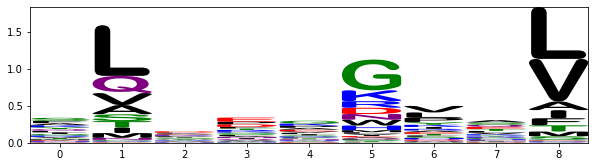

In [62]:
make_logo(bottom_500_not_inf)

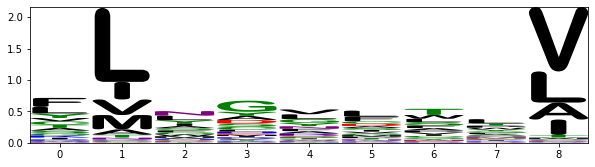

In [63]:
make_logo(top_500)

In [64]:
i_complexity = len(df_i_paths)
b_complexity = len(df_b_paths)

In [65]:
train_df_repr_db['i_score_corrected'] = train_df_repr_db['i_score'] - np.log(i_complexity)
train_df_repr_db['b_score_corrected'] = train_df_repr_db['b_score'] - np.log(b_complexity)
train_df_repr_db['diff_score'] = train_df_repr_db['i_score_corrected'] - train_df_repr_db['b_score_corrected']

In [66]:
top_500 = train_df_repr_db.sort_values('diff_score', ascending=False)[:500]
bottom_500 = train_df_repr_db.sort_values('diff_score', ascending=True)[:500]
df = train_df_repr_db.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

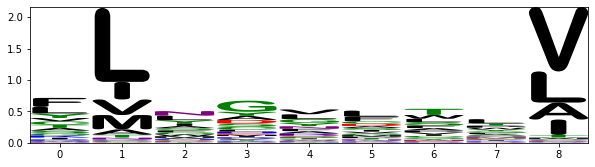

In [67]:
make_logo(top_500)

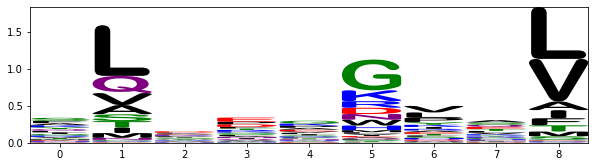

In [68]:
make_logo(bottom_500_not_inf)

In [69]:
top_500

path_index,0,1,2,3,4,5,6,7,8,9,...,188,189,190,191,b_score,i_score,peptide,diff_score,i_score_corrected,b_score_corrected
peptide,,,,,,,,,,,,,,,,,,,,,
CVNGVCWTV,-33.949257,-32.266091,-34.155377,-30.534437,-35.760142,-31.879080,-34.105284,-32.598868,-36.061308,-34.378143,...,-39.171916,-35.290854,-35.466924,-33.960509,-28.354265,-17.731886,CVNGVCWTV,11.027845,-22.583916,-33.611761
CINGVCWTV,-34.895336,-33.212171,-35.101456,-31.480517,-36.706222,-32.825160,-35.051363,-33.544948,-37.007388,-35.324222,...,-36.583956,-32.702894,-32.878965,-31.372549,-28.157839,-17.823303,CINGVCWTV,10.740001,-22.675334,-33.415334
CINGVCWTA,-36.228917,-34.545751,-36.435037,-32.814097,-38.039802,-34.158740,-36.384944,-34.878528,-38.340968,-36.657803,...,-37.917537,-34.036475,-34.212545,-32.706129,-29.491419,-19.384214,CINGVCWTA,10.512670,-24.236244,-34.748915
CINGACWTV,-35.193632,-33.510466,-35.399752,-31.778812,-37.004517,-33.123455,-35.349659,-33.843244,-35.951801,-34.268635,...,-37.120719,-33.239657,-33.415728,-31.909312,-28.347752,-18.945222,CINGACWTV,9.807995,-23.797252,-33.605247
CINGVSWTV,-33.826101,-32.142935,-34.683464,-31.062525,-33.327856,-29.446794,-36.692837,-35.186422,-35.938153,-34.254987,...,-33.205591,-29.324529,-34.520439,-33.014023,-26.425634,-18.992837,CINGVSWTV,7.838263,-23.844867,-31.683130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLWASPVNA,-35.635403,-32.877172,-32.501732,-27.805727,-32.308333,-27.352205,-32.233703,-29.652222,-36.566115,-33.807883,...,-30.814881,-25.858753,-28.690118,-26.108637,-23.101346,-20.978173,LLWASPVNA,2.528638,-25.830203,-28.358842
LLLDDFVEI,-27.820400,-25.062168,-27.967801,-23.271795,-28.631404,-23.675276,-28.864358,-26.282876,-28.972494,-26.214263,...,-32.402086,-27.445958,-30.584907,-28.003426,-20.538104,-18.415894,LLLDDFVEI,2.527676,-23.267924,-25.795599
KMVGLVVAI,-30.895582,-28.137350,-30.521123,-25.825118,-32.294680,-27.338553,-32.725257,-30.143776,-30.304606,-27.546374,...,-32.171638,-27.215510,-30.552082,-27.970601,-22.649997,-20.535420,KMVGLVVAI,2.520042,-25.387451,-27.907492


## Decoy corrected scores

In [70]:
len(decoy_data)

401984

In [71]:
decoy_data['i_score_corrected'] = decoy_data['i_score'] - np.log(i_complexity)
decoy_data['b_score_corrected'] = decoy_data['b_score'] - np.log(b_complexity)
decoy_data['diff_score'] = decoy_data['i_score_corrected'] - decoy_data['b_score_corrected']

In [72]:
sorted_decoy = decoy_data.sort_values('i_score_corrected', ascending=False)

## Difference acros binders

In [73]:
top_percent_binding_value = np.percentile(sorted_decoy['b_score_corrected'].values, 98)
top_percent_binding_value

-28.067412471241624

In [77]:
selected_decoy = sorted_decoy[sorted_decoy['b_score_corrected'] > top_percent_binding_value]

top_500 = selected_decoy.sort_values('diff_score', ascending=False)[:500].copy()
bottom_500 = selected_decoy.sort_values('diff_score', ascending=True)[:500]
df = selected_decoy.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500].copy()

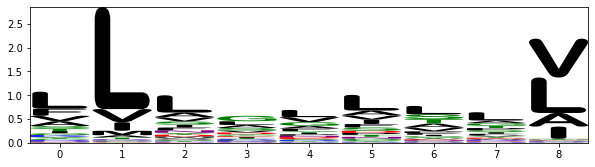

In [78]:
make_logo(top_500)

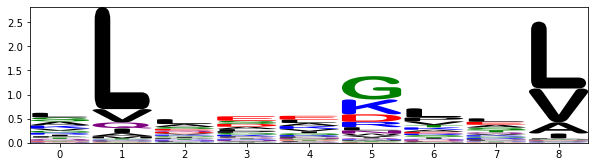

In [79]:
make_logo(bottom_500_not_inf)

## Binding across binders

In [80]:
top_500 = selected_decoy.sort_values('b_score_corrected', ascending=False)[:500]
bottom_500 = selected_decoy.sort_values('b_score_corrected', ascending=True)[:500]
df = selected_decoy.sort_values('b_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['b_score_corrected'])][:500]

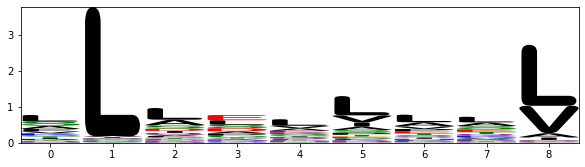

In [81]:
make_logo(top_500)

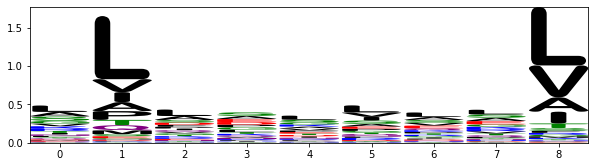

In [82]:
make_logo(bottom_500_not_inf)

## Immunogenicity acros binders

In [83]:
top_500 = selected_decoy.sort_values('i_score_corrected', ascending=False)[:500]
bottom_500 = selected_decoy.sort_values('i_score_corrected', ascending=True)[:500]
df = selected_decoy.sort_values('i_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score_corrected'])][:500]

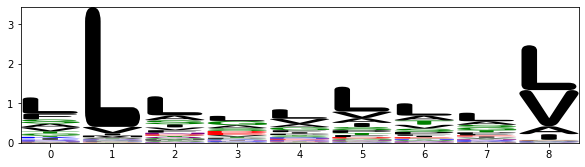

In [84]:
make_logo(top_500)

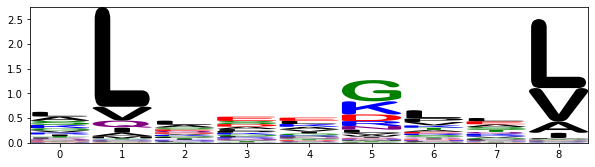

In [85]:
make_logo(bottom_500_not_inf)

## Binding score  across all peptides

In [86]:
top_500 = sorted_decoy.sort_values('b_score_corrected', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('b_score_corrected', ascending=True)[:500]
df = sorted_decoy.sort_values('b_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['b_score_corrected'])][:500]

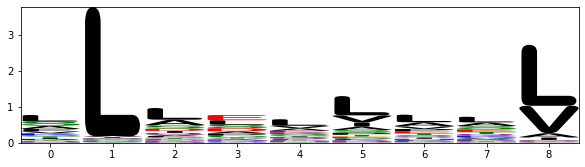

In [87]:
make_logo(top_500)

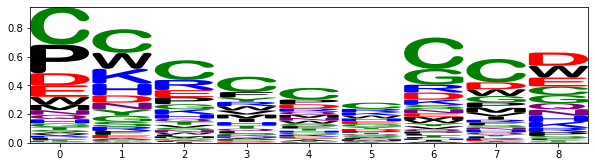

In [88]:
make_logo(bottom_500_not_inf)

## Immunogenicity score across all peptides

In [89]:
top_500 = sorted_decoy.sort_values('i_score_corrected', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('i_score_corrected', ascending=True)[:500]
df = sorted_decoy.sort_values('i_score_corrected', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score_corrected'])][:500]

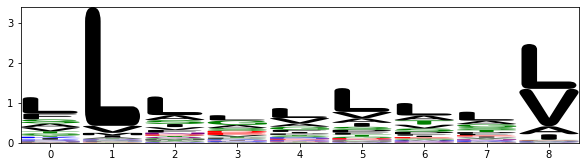

In [90]:
make_logo(top_500)

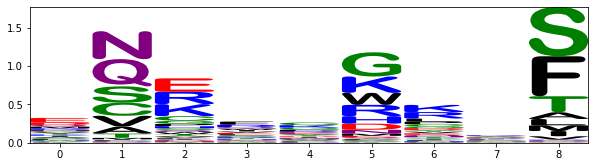

In [91]:
make_logo(bottom_500_not_inf)

## Difference across all peptides

In [92]:
top_500 = sorted_decoy.sort_values('diff_score', ascending=False)[:500]
bottom_500 = sorted_decoy.sort_values('diff_score', ascending=True)[:500]
df = sorted_decoy.sort_values('diff_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['diff_score'])][:500]

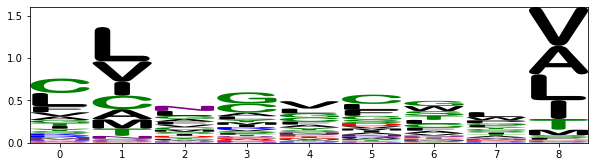

In [93]:
make_logo(top_500)

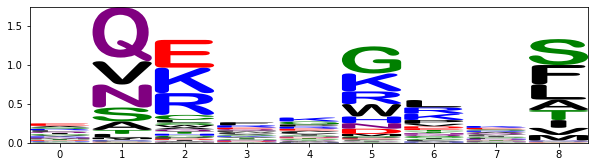

In [94]:
make_logo(bottom_500_not_inf)

## Generated data

In [97]:
generated_df_repr_db = pivot_data_dict['Generated']['db']['mb']
generated_df_repr_di = pivot_data_dict['Generated']['di']['mb']
len(generated_df_repr_db)

3000

In [98]:
generated_df_repr_db['b_score'] =  [model_binding.log_probability(peptide) for peptide in generated_df_repr_db.index.values]
generated_df_repr_db['peptide'] =  generated_df_repr_db.index.values
generated_df_repr_di['b_score'] =  [model_binding.log_probability(peptide) for peptide in generated_df_repr_di.index.values]
generated_df_repr_di['peptide'] =  generated_df_repr_di.index.values

generated_df_repr_db['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in generated_df_repr_db.index.values]
generated_df_repr_di['i_score'] =  [model_immunogenic.log_probability(peptide) for peptide in generated_df_repr_di.index.values]


generated_df_repr_db.head()

path_index,0,1,2,3,4,5,6,7,8,9,...,185,186,187,188,189,190,191,b_score,peptide,i_score
peptide,,,,,,,,,,,,,,,,,,,,,
AADGEAVKL,-30.042521,-27.284289,-34.158153,-29.462147,-33.316927,-28.360799,-32.780395,-30.198913,-33.169309,-30.411077,...,-26.900146,-40.754545,-36.058540,-34.700381,-29.744253,-32.113716,-29.532234,-22.853725,AADGEAVKL,-24.282859
AALAVKSAV,-28.791130,-26.611671,-29.246606,-25.129373,-29.078426,-24.701071,-29.854287,-27.851579,-30.903182,-28.723723,...,-26.921774,-36.537244,-32.420011,-31.156125,-26.778770,-29.881853,-27.879145,-22.833749,AALAVKSAV,-29.095112
AALEDAKVL,-27.247397,-24.758818,-31.363029,-26.936676,-30.521803,-25.835327,-29.985271,-27.673442,-28.399492,-25.910913,...,-29.737088,-43.321834,-38.895481,-37.267670,-32.581194,-34.681005,-32.369176,-23.372709,AALEDAKVL,-26.110746
AALSAVHAV,-28.003724,-24.775975,-27.629265,-22.463743,-29.402823,-23.977178,-29.833400,-26.782401,-28.761893,-25.534144,...,-25.777573,-35.611399,-30.445876,-32.172017,-26.746372,-30.552461,-27.501463,-21.244285,AALSAVHAV,-22.670943
AANDTLIFL,-27.977013,-27.047271,-27.610532,-24.743016,-28.148878,-25.021239,-33.104413,-32.351421,-29.054020,-28.124279,...,-27.680371,-35.224167,-32.356651,-30.549574,-27.421936,-33.454976,-32.701985,-22.308689,AANDTLIFL,-21.820492


In [107]:
top_500 = generated_df_repr_db.sort_values('i_score', ascending=False)[:500]
bottom_500 = generated_df_repr_db.sort_values('i_score', ascending=True)[:500]
df = generated_df_repr_db.sort_values('i_score', ascending=True)
bottom_500_not_inf = df[~np.isinf(df['i_score'])][:500]

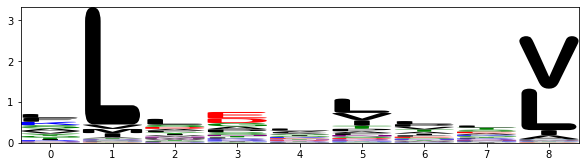

In [108]:
make_logo(top_500)

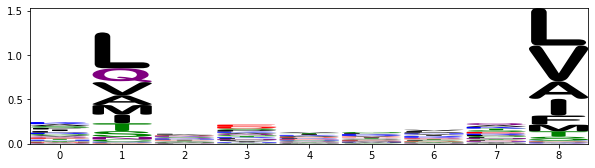

In [109]:
make_logo(bottom_500_not_inf)